In [1]:
!pip install -q skorch

import os, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(42); np.random.seed(42)
os.makedirs("/kaggle/working/images", exist_ok=True)
print("Device :", device)

Device : cpu


In [2]:
for root, _, files in os.walk("/kaggle/input"):
    for f in files:
        print(os.path.join(root, f))

/kaggle/input/datasets/dgawlik/nyse/fundamentals.csv
/kaggle/input/datasets/dgawlik/nyse/prices-split-adjusted.csv
/kaggle/input/datasets/dgawlik/nyse/prices.csv
/kaggle/input/datasets/dgawlik/nyse/securities.csv


In [4]:
df = pd.read_csv("/kaggle/input/datasets/dgawlik/nyse/prices-split-adjusted.csv", parse_dates=["date"])
print(df.shape); df.head()

(851264, 7)


,date,symbol,open,close,low,high,volume
0,2016-01-05,WLTW,123.430000,125.839996,122.309998,126.250000,2163600.0
1,2016-01-06,WLTW,125.239998,119.980003,119.940002,125.540001,2386400.0
2,2016-01-07,WLTW,116.379997,114.949997,114.930000,119.739998,2489500.0
3,2016-01-08,WLTW,115.480003,116.620003,113.500000,117.440002,2006300.0
4,2016-01-11,WLTW,117.010002,114.970001,114.089996,117.330002,1408600.0


In [5]:
df.info()
print(df.describe())
print("Manquants :\n", df.isna().sum())
print("Doublons :", df.duplicated().sum())
print("Symboles :", df.symbol.nunique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 851264 entries, 0 to 851263
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype         
---  ------  --------------   -----         
 0   date    851264 non-null  datetime64[ns]
 1   symbol  851264 non-null  object        
 2   open    851264 non-null  float64       
 3   close   851264 non-null  float64       
 4   low     851264 non-null  float64       
 5   high    851264 non-null  float64       
 6   volume  851264 non-null  float64       
dtypes: datetime64[ns](1), float64(5), object(1)
memory usage: 45.5+ MB
                                date           open          close  \
count                         851264  851264.000000  851264.000000   
mean   2013-07-21 02:56:29.294037760      64.993618      65.011913   
min              2010-01-04 00:00:00       1.660000       1.590000   
25%              2011-10-19 00:00:00      31.270000      31.292776   
50%              2013-08-02 00:00:00      48.459999      48.480

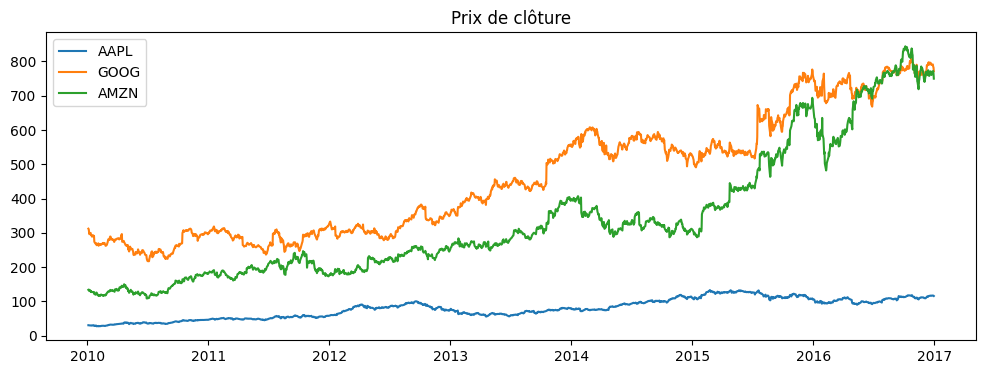

In [7]:
plt.figure(figsize=(12,4))
for s in ["AAPL", "GOOG", "AMZN"]:
    d = df[df.symbol == s]; plt.plot(d.date, d.close, label=s)
plt.legend(); plt.title("Prix de clôture"); plt.savefig("/kaggle/working/images/p1_prix.png"); plt.show()

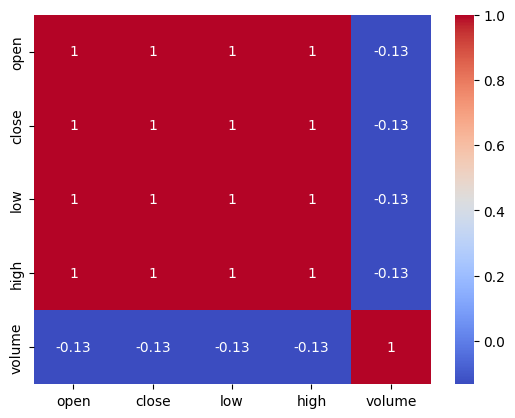

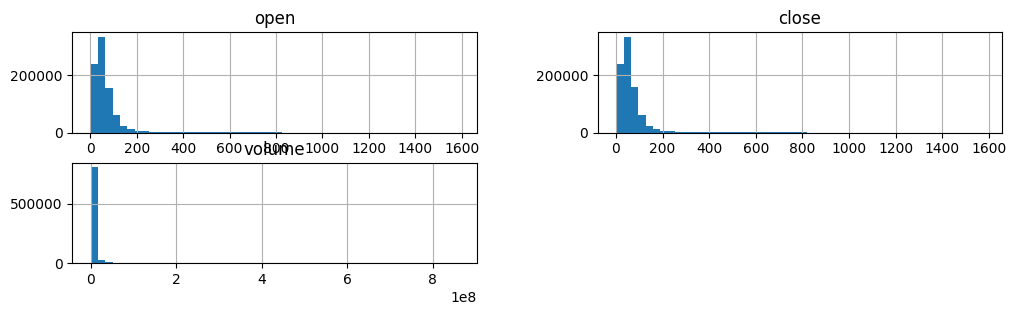

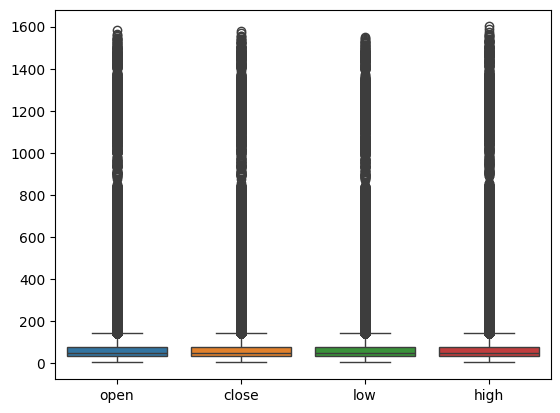

In [8]:
sns.heatmap(df[["open","close","low","high","volume"]].corr(), annot=True, cmap="coolwarm")
plt.savefig("/kaggle/working/images/p1_corr.png"); plt.show()

df[["open","close","volume"]].hist(bins=50, figsize=(12,3)); plt.show()
sns.boxplot(data=df[["open","close","low","high"]]); plt.show()

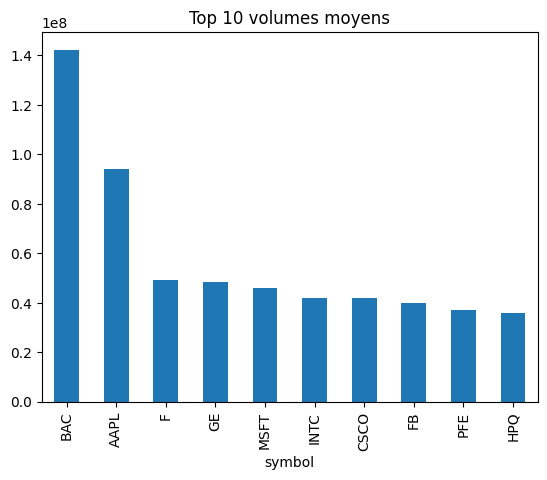

In [9]:
df.groupby("symbol")["volume"].mean().nlargest(10).plot.bar(title="Top 10 volumes moyens")
plt.show()

In [10]:
df["volume"] = np.log1p(df["volume"])
d = df.sample(200_000, random_state=42)      # échantillon pour limiter le temps de calcul

X = d[["open","low","high","volume"]].values.astype("float32")
y = d["close"].values.astype("float32").reshape(-1,1)

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)
sx, sy = StandardScaler(), StandardScaler()
X_tr = sx.fit_transform(X_tr).astype("float32"); X_te = sx.transform(X_te).astype("float32")
y_tr = sy.fit_transform(y_tr).astype("float32"); y_te = sy.transform(y_te).astype("float32")
print(X_tr.shape, X_te.shape)

(160000, 4) (40000, 4)


In [12]:
class MLPReg(nn.Module):
    def __init__(self, n_in=4, hidden=64, n_layers=2, dropout=0.0, batchnorm=False):
        super().__init__()
        layers, dim = [], n_in
        for _ in range(n_layers):
            layers.append(nn.Linear(dim, hidden))
            if batchnorm: layers.append(nn.BatchNorm1d(hidden))
            layers += [nn.ReLU(), nn.Dropout(dropout)]
            dim = hidden
        layers.append(nn.Linear(dim, 1))
        self.net = nn.Sequential(*layers)
    def forward(self, x): return self.net(x)

In [13]:
from skorch import NeuralNetRegressor

net = NeuralNetRegressor(MLPReg, criterion=nn.MSELoss, optimizer=torch.optim.Adam,
                         max_epochs=20, batch_size=256, lr=1e-3,
                         device=device, verbose=0, train_split=None)
params = {
    "lr": [1e-2, 1e-3],
    "optimizer": [torch.optim.Adam, torch.optim.SGD, torch.optim.RMSprop],
    "max_epochs": [20, 40],
    "module__hidden": [32, 64],
    "module__n_layers": [1, 2],
}
gs = GridSearchCV(net, params, cv=3, scoring="r2", n_jobs=1, verbose=1)
gs.fit(X_tr[:30000], y_tr[:30000])
print(gs.best_params_, gs.best_score_)
pd.DataFrame(gs.cv_results_).sort_values("rank_test_score").head()

Fitting 3 folds for each of 48 candidates, totalling 144 fits
{'lr': 0.01, 'max_epochs': 40, 'module__hidden': 32, 'module__n_layers': 1, 'optimizer': <class 'torch.optim.adam.Adam'>} 0.9998360474904379


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_lr,param_max_epochs,param_module__hidden,param_module__n_layers,param_optimizer,params,split0_test_score,split1_test_score,split2_test_score,mean_test_score,std_test_score,rank_test_score
12,10.752646,0.079045,0.125038,0.004733,0.010,40,32,1,<class 'torch.optim.adam.Adam'>,"{'lr': 0.01, 'max_epochs': 40, 'module__hidden...",0.999868,0.999794,0.999847,0.999836,0.000031,1
33,6.060248,0.063421,0.127094,0.002313,0.001,20,64,2,<class 'torch.optim.adam.Adam'>,"{'lr': 0.001, 'max_epochs': 20, 'module__hidde...",0.999817,0.999862,0.999801,0.999827,0.000026,2
39,12.057469,0.255306,0.131855,0.001887,0.001,40,32,2,<class 'torch.optim.adam.Adam'>,"{'lr': 0.001, 'max_epochs': 40, 'module__hidde...",0.999831,0.999861,0.999782,0.999825,0.000033,3
26,5.199015,0.065832,0.123210,0.001774,0.001,20,32,1,<class 'torch.optim.rmsprop.RMSprop'>,"{'lr': 0.001, 'max_epochs': 20, 'module__hidde...",0.999796,0.999859,0.999819,0.999825,0.000026,4
45,12.685274,0.198761,0.139590,0.006102,0.001,40,64,2,<class 'torch.optim.adam.Adam'>,"{'lr': 0.001, 'max_epochs': 40, 'module__hidde...",0.999817,0.999812,0.999843,0.999824,0.000014,5


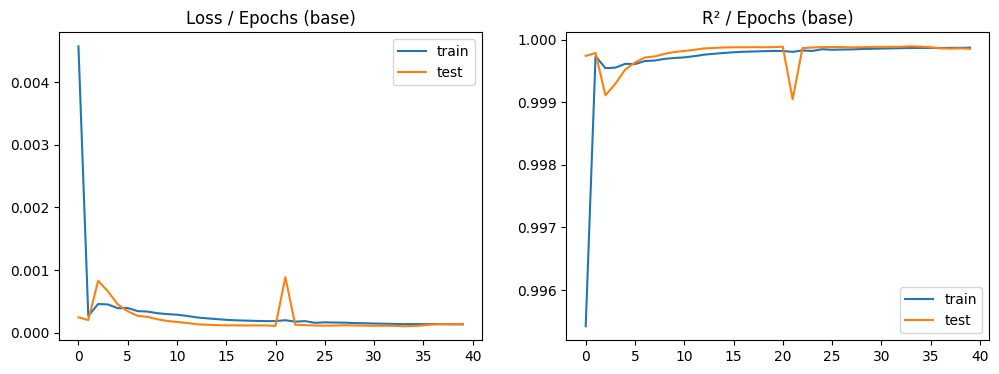

In [14]:
from skorch.callbacks import EpochScoring
from skorch.helper import predefined_split
from skorch.dataset import Dataset

best = gs.best_params_
def build(**override):
    p = {**best, **override}
    return NeuralNetRegressor(MLPReg, criterion=nn.MSELoss, device=device, batch_size=256,
        verbose=0, train_split=predefined_split(Dataset(X_te, y_te)),
        callbacks=[EpochScoring("r2", name="train_r2", on_train=True, lower_is_better=False),
                   EpochScoring("r2", name="valid_r2", lower_is_better=False)], **p)

net_base = build(); net_base.fit(X_tr, y_tr)

def plot_hist(net, title, fn):
    h = net.history
    fig, ax = plt.subplots(1,2, figsize=(12,4))
    ax[0].plot(h[:,"train_loss"], label="train"); ax[0].plot(h[:,"valid_loss"], label="test")
    ax[0].set_title(f"Loss / Epochs ({title})"); ax[0].legend()
    ax[1].plot(h[:,"train_r2"], label="train"); ax[1].plot(h[:,"valid_r2"], label="test")
    ax[1].set_title(f"R² / Epochs ({title})"); ax[1].legend()
    plt.savefig(f"/kaggle/working/images/{fn}.png"); plt.show()

plot_hist(net_base, "base", "p1_base")

In [15]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def metrics(net, name):
    out = {"modèle": name}
    for nm, Xs, ys in [("train", X_tr, y_tr), ("test", X_te, y_te)]:
        yp = sy.inverse_transform(net.predict(Xs)); yt = sy.inverse_transform(ys)
        out[f"RMSE_{nm}"] = np.sqrt(mean_squared_error(yt, yp))
        out[f"MAE_{nm}"]  = mean_absolute_error(yt, yp)
        out[f"R2_{nm}"]   = r2_score(yt, yp)
    return out

results = [metrics(net_base, "Base")]
pd.DataFrame(results)

,modèle,RMSE_train,MAE_train,R2_train,RMSE_test,MAE_test,R2_test
0,Base,0.941861,0.394686,0.999845,0.891415,0.389177,0.999851


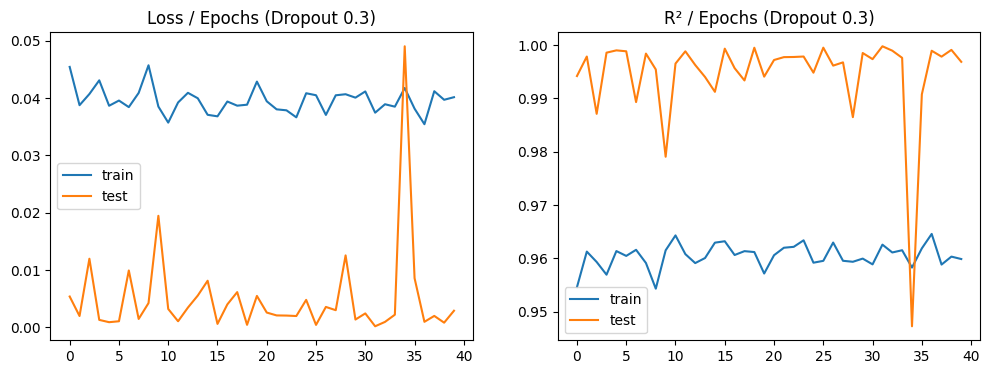

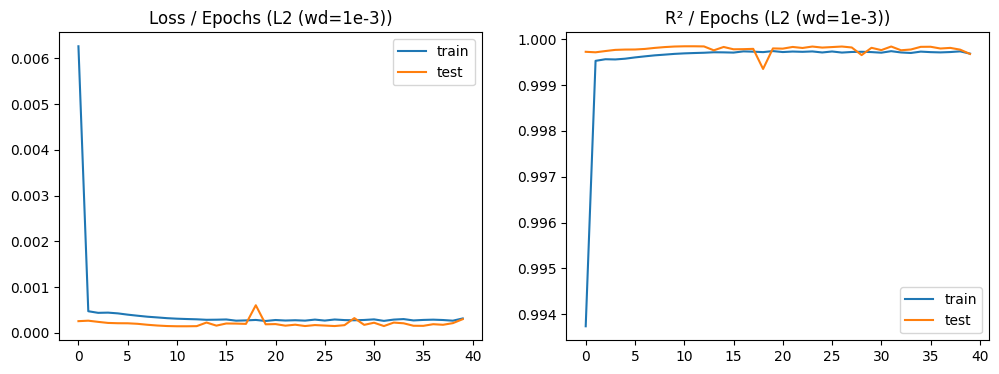

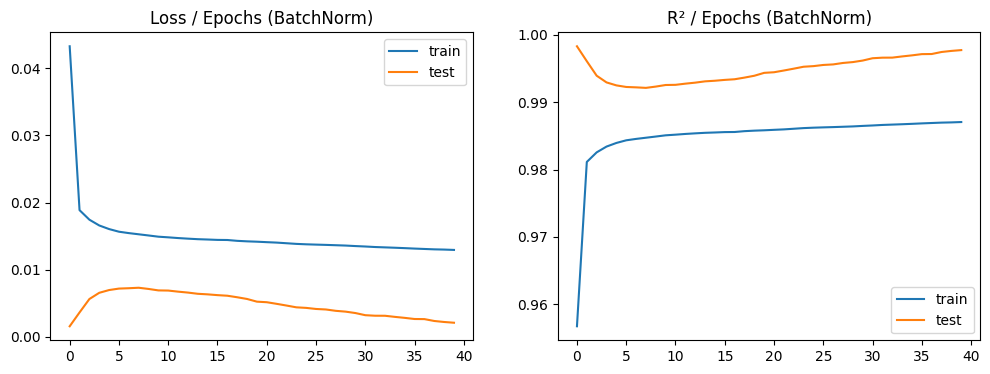

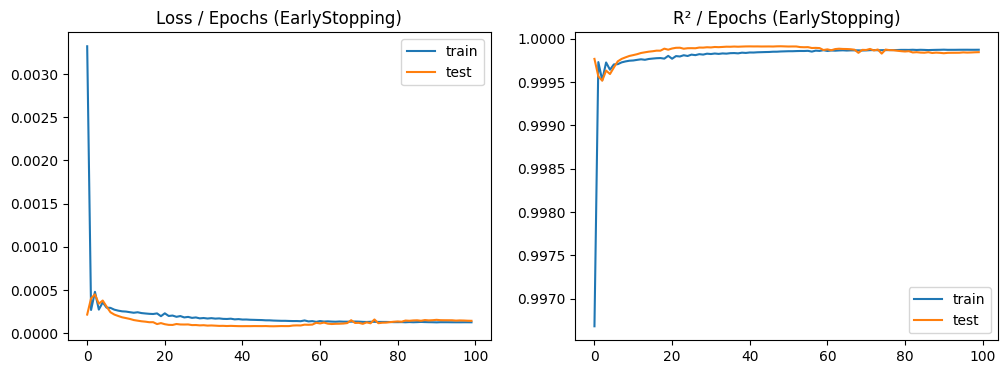

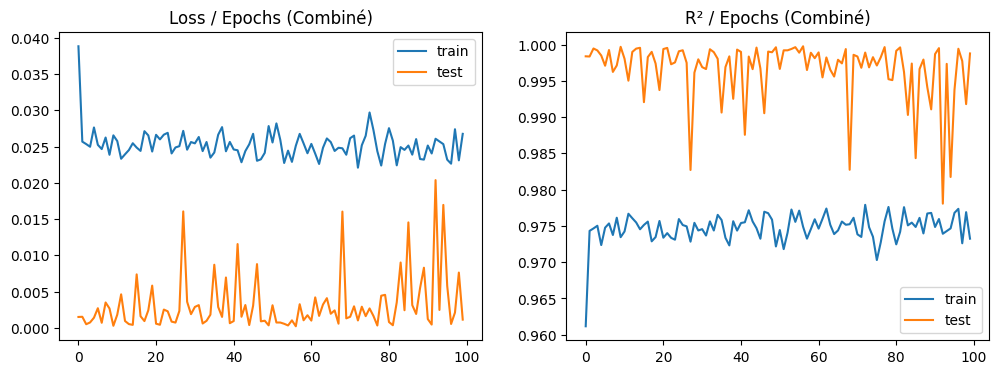

,modèle,RMSE_train,MAE_train,R2_train,RMSE_test,MAE_test,R2_test
0,Base,0.941861,0.394686,0.999845,0.891415,0.389177,0.999851
1,Dropout 0.3,7.868988,3.748054,0.989202,7.526058,3.713341,0.989369
2,Dropout 0.3,4.144991,2.300101,0.997004,4.088633,2.276186,0.996862
3,L2 (wd=1e-3),1.329813,0.860670,0.999692,1.310895,0.862122,0.999677
4,BatchNorm,3.583032,2.337294,0.997761,3.468159,2.329279,0.997742
5,EarlyStopping,0.959010,0.451966,0.999840,0.904818,0.446970,0.999846
6,Combiné,2.557495,1.852895,0.998859,2.551889,1.850894,0.998778


In [17]:
from skorch.callbacks import EarlyStopping

configs = {
    "Dropout 0.3":   dict(module__dropout=0.3),
    "L2 (wd=1e-3)":  dict(optimizer__weight_decay=1e-3),
    "BatchNorm":     dict(module__batchnorm=True),
    "EarlyStopping": dict(max_epochs=100, callbacks__early=EarlyStopping(patience=5)),
    "Combiné":       dict(module__dropout=0.2, optimizer__weight_decay=1e-4, max_epochs=100,
                          callbacks__early=EarlyStopping(patience=5)),
}
nets = {"Base": net_base}
for name, kw in configs.items():
    n = build(**kw); n.fit(X_tr, y_tr); nets[name] = n
    results.append(metrics(n, name)); plot_hist(n, name, "p1_" + name.split()[0])

res = pd.DataFrame(results); res.to_csv("/kaggle/working/p1_resultats.csv", index=False)
res